In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.style.use('default')
url = 'https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv'

In [17]:
births = pd.read_csv(url)
print(births.head())                 # first five rows
print("Shape:", births.shape)        # expected: (15547, 5)
print(births.dtypes)

   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548
Shape: (15547, 5)
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object


gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
M > F in every decade: True
        M/F ratio  M exceeds F by (%)
decade                               
1960     1.052997            5.299738
1970     1.052787            5.278676
1980     1.050960            5.096030
1990     1.048312            4.831239
2000     1.048116            4.811587


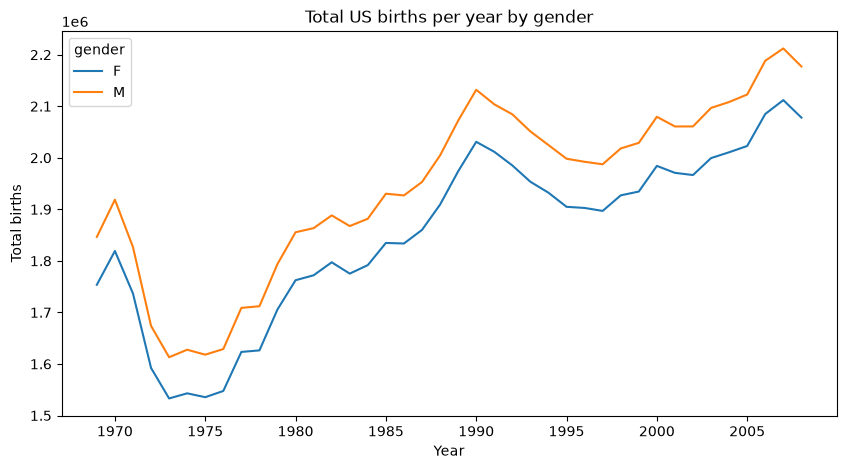

In [18]:
births['decade'] = 10 * (births['year'] // 10)

pt = births.pivot_table('births', index='decade', columns='gender', aggfunc='sum')
print(pt)

# (a) Verify males > females in every decade
print("M > F in every decade:", (pt['M'] > pt['F']).all())

# (b) Ratio and percentage excess
summary = pd.DataFrame({
    'M/F ratio': pt['M'] / pt['F'],
    'M exceeds F by (%)': (pt['M'] / pt['F'] - 1) * 100
})
print(summary)

# (c) Total births per year by gender
yearly = births.pivot_table('births', index='year', columns='gender', aggfunc='sum')
ax = yearly.plot(figsize=(10, 5))
ax.set_xlabel('Year')
ax.set_ylabel('Total births')
ax.set_title('Total US births per year by gender')
plt.show()

In [19]:
# (a) Robust statistics
quartiles = np.percentile(births['births'], [25, 50, 75])
mu = quartiles[1]                              # median as robust mean
sig = 0.74 * (quartiles[2] - quartiles[0])     # robust std from the IQR
print(quartiles, mu, sig)

# (b) Keep rows within 5 sigma of mu
n_before = len(births)
births = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)')
print("Rows removed:", n_before - len(births))

# (c) Convert day to int
births['day'] = births['day'].astype(int)
print(births.dtypes)

[4358.  4814.  5289.5] 4814.0 689.31
Rows removed: 937
year      int64
month     int64
day       int64
gender      str
births    int64
decade    int64
dtype: object


            year  month  day gender  births  decade  dayofweek
1969-01-01  1969      1    1      F    4046    1960          2
1969-01-01  1969      1    1      M    4440    1960          2
1969-01-02  1969      1    2      F    4454    1960          3
1969-01-02  1969      1    2      M    4548    1960          3
1969-01-03  1969      1    3      F    4548    1960          4


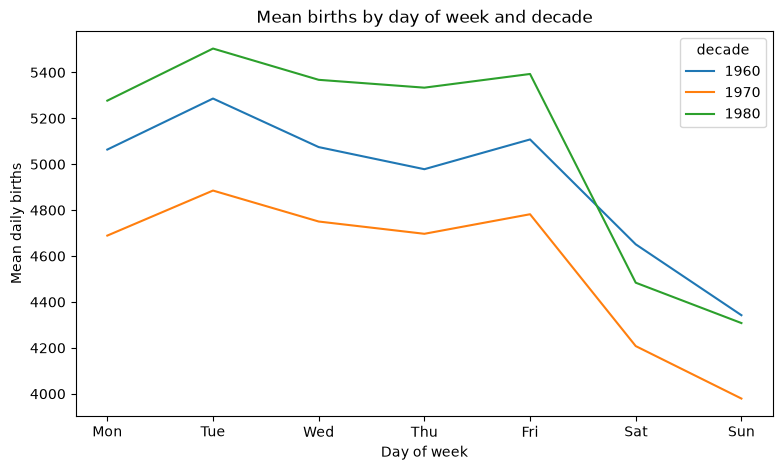

In [27]:
# (a) Build DatetimeIndex
births.index = pd.to_datetime(10000 * births['year'] +
                              100 * births['month'] +
                              births['day'], format='%Y%m%d')
births['dayofweek'] = births.index.dayofweek      # Mon=0 ... Sun=6
print(births.head())
# (b) Mean births by weekday and decade
dow = births.pivot_table('births', index='dayofweek', columns='decade', aggfunc='mean')
ax = dow.plot(figsize=(9, 5))
ax.set_xticks(range(7))
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xlabel('Day of week')
ax.set_ylabel('Mean daily births')
ax.set_title('Mean births by day of week and decade')
plt.show()

       births
1 1  4009.225
  2  4247.400
  3  4500.900
  4  4571.350
  5  4603.625
              births
2012-01-01  4009.225
2012-01-02  4247.400
2012-01-03  4500.900
2012-01-04  4571.350
2012-01-05  4603.625


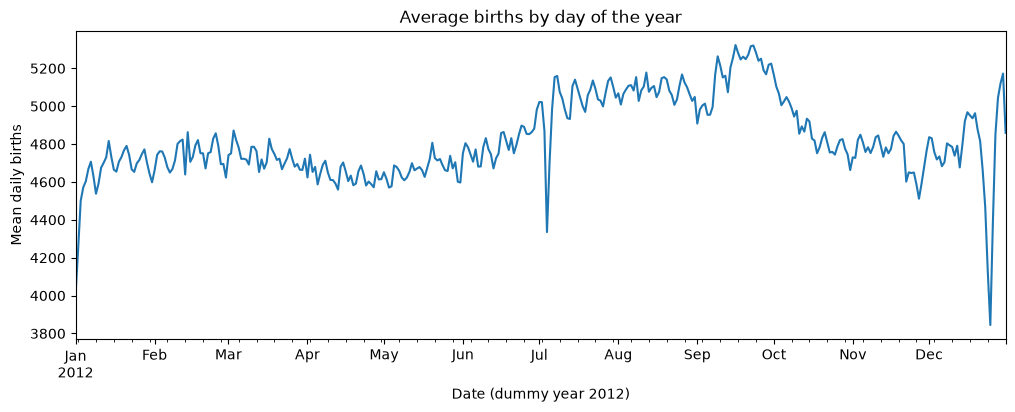

In [28]:
# Mean births for each (month, day)
by_date = births.pivot_table('births',
                             [births.index.month, births.index.day])
print(by_date.head())

# (a) Convert multi-index to dates with a dummy leap year

# (a vectorized alternative:)
# idx = pd.to_datetime(dict(year=2012, month=by_date.index.get_level_values(0),
#                           day=by_date.index.get_level_values(1)))
by_date.index = pd.to_datetime(dict(
    year=2012,
month=by_date.index.get_level_values(0),
    day=by_date.index.get_level_values(1)))
print(by_date.head())
# (b) Plot
fig, ax = plt.subplots(figsize=(12, 4))
by_date.plot(ax=ax, legend=False)
ax.set_xlabel('Date (dummy year 2012)')
ax.set_ylabel('Mean daily births')
ax.set_title('Average births by day of the year')
plt.show()

In [24]:
import timeit

t_pivot = timeit.timeit(
    lambda: births.pivot_table('births', index='decade',
                               columns='gender', aggfunc='sum'),
    number=100) / 100
t_group = timeit.timeit(
    lambda: births.groupby(['decade', 'gender'])['births'].sum().unstack(),
    number=100) / 100

print(f"pivot_table: {t_pivot*1000:.2f} ms | groupby: {t_group*1000:.2f} ms")

pivot_table: 18.55 ms | groupby: 6.79 ms


In [25]:
# (a) Rebuild both tables from the same (cleaned) DataFrame
pt = births.pivot_table('births', index='decade',
                        columns='gender', aggfunc='sum')
gb = births.groupby(['decade', 'gender'])['births'].sum().unstack()

print(gb)
print("Values match:", np.allclose(gb.values, pt.values))
print("Fully equal :", gb.equals(pt))

gender         F         M
decade                    
1960     1752836   1845742
1970    16260348  17118785
1980    16336507  17171290
Values match: True
Fully equal : True


2012-12-25    3844.450
2012-01-01    4009.225
2012-12-24    4126.250
2012-01-02    4247.400
2012-07-04    4335.325
Name: births, dtype: float64


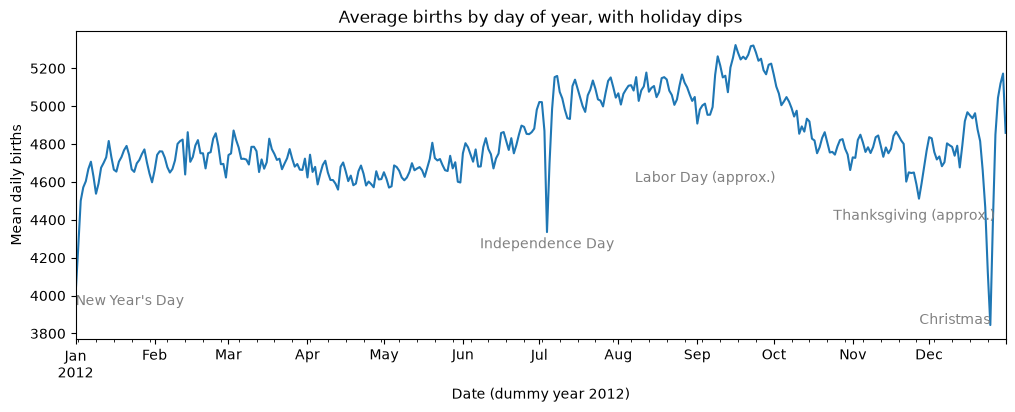

In [26]:
lowest5 = by_date['births'].nsmallest(5)
print(lowest5)

fig, ax = plt.subplots(figsize=(12, 4))
by_date.plot(ax=ax, legend=False)
ax.set_xlabel('Date (dummy year 2012)')
ax.set_ylabel('Mean daily births')
ax.set_title('Average births by day of year, with holiday dips')

style = dict(size=10, color='gray')
ax.text('2012-1-1', 3950, "New Year's Day", **style)
ax.text('2012-7-4', 4250, "Independence Day", ha='center', **style)
ax.text('2012-12-25', 3850, "Christmas", ha='right', **style)
# Optional additional labels:
ax.text('2012-9-4', 4600, "Labor Day (approx.)", ha='center', **style)
ax.text('2012-11-25', 4400, "Thanksgiving (approx.)", ha='center', **style)
plt.show()